In [3]:
import pandas as pd
df = pd.read_csv("HR-Analytics-Employee.csv")


In [4]:
print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["Attrition"].value_counts())

Dataset Shape: (1470, 35)

Class Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=[
    "Attrition", "EmployeeNumber",
    "EmployeeCount", "Over18", "StandardHours"
])

y = df["Attrition"].map({"Yes": 1, "No": 0})

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [6]:

from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_under, y_train_under = rus.fit_resample(
    X_train, y_train
)


In [7]:

print("Before Undersampling:")
print(y_train.value_counts())
print("Shape:", X_train.shape)

print("\nAfter Undersampling:")
print(y_train_under.value_counts())
print("Shape:", X_train_under.shape)


Before Undersampling:
Attrition
0    986
1    190
Name: count, dtype: int64
Shape: (1176, 30)

After Undersampling:
Attrition
0    190
1    190
Name: count, dtype: int64
Shape: (380, 30)


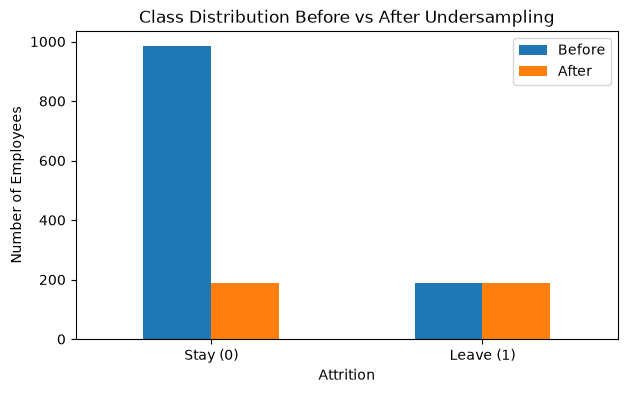

In [8]:

import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Before": y_train.value_counts().sort_index(),
    "After": y_train_under.value_counts().sort_index()
})

comparison.index = ["Stay (0)", "Leave (1)"]

comparison.plot(kind="bar", figsize=(7, 4))

plt.title("Class Distribution Before vs After Undersampling")
plt.ylabel("Number of Employees")
plt.xlabel("Attrition")
plt.xticks(rotation=0)
plt.show()


In [9]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

ordinal_cols = [
    "Education", "EnvironmentSatisfaction",
    "JobInvolvement", "JobLevel",
    "JobSatisfaction", "PerformanceRating",
    "RelationshipSatisfaction", "WorkLifeBalance"
]

numeric_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in ordinal_cols
]

categorical_cols = (
    X_train.select_dtypes(exclude="number").columns.tolist()
    + ordinal_cols
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


In [10]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

under_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

under_model.fit(X_train_under, y_train_under)

print("Model trained successfully!")


Model trained successfully!


In [11]:

from sklearn.metrics import classification_report, confusion_matrix

# Predict on original test data
y_pred_under = under_model.predict(X_test)

# Evaluation
print("Classification Report:")
print(classification_report(y_test, y_pred_under))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_under))


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.78      0.85       247
           1       0.38      0.70      0.49        47

    accuracy                           0.77       294
   macro avg       0.65      0.74      0.67       294
weighted avg       0.84      0.77      0.79       294


Confusion Matrix:
[[192  55]
 [ 14  33]]


In [12]:

rus_60 = RandomUnderSampler(
    sampling_strategy=2/3,
    random_state=42
)

X_train_under60, y_train_under60 = rus_60.fit_resample(
    X_train, y_train
)

print(y_train_under60.value_counts())


Attrition
0    285
1    190
Name: count, dtype: int64


In [13]:

from sklearn.base import clone

# Create a fresh copy of the previous model
under_model_60 = clone(under_model)

# Train using 60/40 data
under_model_60.fit(X_train_under60, y_train_under60)

print("Model trained successfully!")


Model trained successfully!


In [14]:

# Predict using the same original test set
y_pred_under60 = under_model_60.predict(X_test)

print("Classification Report - 60/40:")
print(classification_report(y_test, y_pred_under60))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_under60))


Classification Report - 60/40:
              precision    recall  f1-score   support

           0       0.92      0.85      0.88       247
           1       0.44      0.60      0.50        47

    accuracy                           0.81       294
   macro avg       0.68      0.72      0.69       294
weighted avg       0.84      0.81      0.82       294


Confusion Matrix:
[[211  36]
 [ 19  28]]
